# 🤖 03 - Model Training & Evaluation (3 Mô hình theo đề bài)

Huấn luyện và đánh giá 3 thuật toán phân loại cốt lõi quy định trong đề bài:
- **1. Logistic Regression**: Phân loại nhị phân dựa trên hàm Sigmoid / Logistic function
- **2. Support Vector Machines (SVM)**: Tìm siêu phẳng phân tách lề cực đại (Maximum Margin Hyperplane)
- **3. Naive Bayes**: Mô hình xác suất dựa trên định lý Bayes (Multinomial / Complement Naive Bayes)
- **4. Đánh giá đa chiều trên tập Validation**: Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC-AUC
- **5. Trực quan hóa và so sánh hiệu năng** giữa 3 mô hình


In [1]:
import sys
from pathlib import Path

# Đảm bảo nạp đúng mã nguồn từ thư mục gốc của đồ án
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

from src.models.classifiers import (
    LogisticRegressionFromScratch,
    LinearSVMFromScratch,
    NaiveBayesClassifier,
    get_baseline_models,
)
from src.evaluation.metrics import SpamModelEvaluator

# Nạp dữ liệu bộ đệm đã xử lý từ Task 1
print('Nạp dữ liệu từ data/processed/...')
X_train = sp.load_npz(PROJECT_ROOT / 'data/processed/X_train.npz')
y_train = np.load(PROJECT_ROOT / 'data/processed/y_train.npy')
X_val = sp.load_npz(PROJECT_ROOT / 'data/processed/X_val.npz')
y_val = np.load(PROJECT_ROOT / 'data/processed/y_val.npy')
df_dataset_info = pd.DataFrame([
    {
        "Tập dữ liệu": "Tập huấn luyện (Train)",
        "Kích thước ma trận (Shape)": str(X_train.shape),
        "Tổng số mẫu": f"{X_train.shape[0]:,}",
        "Số chiều đặc trưng": f"{X_train.shape[1]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_train == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_train == 1) / len(y_train) * 100):.2f}%"
    },
    {
        "Tập dữ liệu": "Tập kiểm định (Validation)",
        "Kích thước ma trận (Shape)": str(X_val.shape),
        "Tổng số mẫu": f"{X_val.shape[0]:,}",
        "Số chiều đặc trưng": f"{X_val.shape[1]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_val == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_val == 1) / len(y_val) * 100):.2f}%"
    },

])
display(df_dataset_info)

evaluator = SpamModelEvaluator()
from src.config import NOTEBOOK_SAVED_MODELS_DIR, NOTEBOOK_METRICS_DIR, PROCESSED_DATA_DIR
from src.models.persistence import load_spam_pipeline, save_spam_pipeline
artifacts = load_spam_pipeline(NOTEBOOK_SAVED_MODELS_DIR / 'feature_artifacts.joblib')
assert artifacts['run_id'] == (PROCESSED_DATA_DIR / 'notebook_run_id.txt').read_text(encoding='utf-8').strip(), 'Hãy chạy lại notebook 02.'
config = artifacts['config']
print('Baseline: cùng đặc trưng sau Top-K; metrics Accuracy, Precision, Recall, F1, F2, ROC-AUC trên Validation.')

from hashlib import sha256
if not artifacts.get('cache_sha256'):
    raise RuntimeError('Cache thiếu manifest: chạy lại notebook 02–04.')
for filename, expected_hash in artifacts['cache_sha256'].items():
    actual_hash=sha256((PROCESSED_DATA_DIR/filename).read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        raise RuntimeError(f'Cache không khớp artifacts: {filename}; chạy lại notebook 02–04.')
print('PASS: hash ma trận, nhãn và CSV khớp artifacts.')


Nạp dữ liệu từ data/processed/...
                  Tập dữ liệu  ... Tỷ lệ Spam (%)
0      Tập huấn luyện (Train)  ...         42.69%
1  Tập kiểm định (Validation)  ...         42.68%

[2 rows x 6 columns]
Baseline: cùng đặc trưng sau Top-K; metrics Accuracy, Precision, Recall, F1, F2, ROC-AUC trên Validation.
PASS: hash ma trận, nhãn và CSV khớp artifacts.


## 1. Huấn luyện Mô hình 1: Logistic Regression


In [2]:
# Huấn luyện mô hình 1: Logistic Regression From-Scratch
lr_model = LogisticRegressionFromScratch(
    C=1.0, learning_rate=1.0, max_iter=150, class_weight='balanced', random_state=config.random_state
)
print('Đang huấn luyện Logistic Regression From-Scratch...')
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_val, threshold=0.5)
y_prob_lr = lr_model.predict_proba(X_val)[:, 1]

metrics_lr = evaluator.compute_all_metrics(y_val, y_pred_lr, y_prob=y_prob_lr, beta=2.0)

# Bảng kết quả đánh giá Logistic Regression dạng DataFrame
df_metrics_lr = pd.DataFrame([{
    "Mô hình": "Logistic Regression (From-Scratch)",
    "Tập đánh giá": "Validation Set (10%)",
    "Accuracy": round(metrics_lr['accuracy'], 4),
    "Precision": round(metrics_lr['precision'], 4),
    "Recall": round(metrics_lr['recall'], 4),
    "F1-Score": round(metrics_lr['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_lr['f_beta'], 4),
    "ROC-AUC": round(metrics_lr['roc_auc'], 4),
}])
display(df_metrics_lr)


Đang huấn luyện Logistic Regression From-Scratch...
                              Mô hình  ... ROC-AUC
0  Logistic Regression (From-Scratch)  ...  0.8024

[1 rows x 8 columns]


## 2. Huấn luyện Mô hình 2: Support Vector Machines (SVM)


In [3]:
# Huấn luyện mô hình 2: Support Vector Machines (Linear SVM) From-Scratch
svm_model = LinearSVMFromScratch(
    C=1.0, learning_rate=0.5, max_iter=100, class_weight='balanced', random_state=config.random_state
)
print('Đang huấn luyện Linear SVM From-Scratch...')
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_val, threshold=0.0)
y_prob_svm = svm_model.predict_proba(X_val)[:, 1]

metrics_svm = evaluator.compute_all_metrics(y_val, y_pred_svm, y_prob=y_prob_svm, beta=2.0)

# Bảng kết quả đánh giá Linear SVM dạng DataFrame
df_metrics_svm = pd.DataFrame([{
    "Mô hình": "Linear SVM (From-Scratch)",
    "Tập đánh giá": "Validation Set (10%)",
    "Accuracy": round(metrics_svm['accuracy'], 4),
    "Precision": round(metrics_svm['precision'], 4),
    "Recall": round(metrics_svm['recall'], 4),
    "F1-Score": round(metrics_svm['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_svm['f_beta'], 4),
    "ROC-AUC": round(metrics_svm['roc_auc'], 4),
}])
display(df_metrics_svm)


Đang huấn luyện Linear SVM From-Scratch...
                     Mô hình          Tập đánh giá  ...  F-Beta (Beta=2.0)  ROC-AUC
0  Linear SVM (From-Scratch)  Validation Set (10%)  ...              0.723   0.7999

[1 rows x 8 columns]


## 3. Huấn luyện Mô hình 3: Naive Bayes


In [4]:
# Huấn luyện mô hình 3: Naive Bayes (Complement) From-Scratch
nb_model = NaiveBayesClassifier(alpha=1.0, kind='complement')
print('Đang huấn luyện Complement Naive Bayes From-Scratch...')
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_val, threshold=0.5)
y_prob_nb = nb_model.predict_proba(X_val)[:, 1]

metrics_nb = evaluator.compute_all_metrics(y_val, y_pred_nb, y_prob=y_prob_nb, beta=2.0)

# Bảng kết quả đánh giá Complement Naive Bayes dạng DataFrame
df_metrics_nb = pd.DataFrame([{
    "Mô hình": "Complement Naive Bayes (From-Scratch)",
    "Tập đánh giá": "Validation Set (10%)",
    "Accuracy": round(metrics_nb['accuracy'], 4),
    "Precision": round(metrics_nb['precision'], 4),
    "Recall": round(metrics_nb['recall'], 4),
    "F1-Score": round(metrics_nb['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_nb['f_beta'], 4),
    "ROC-AUC": round(metrics_nb['roc_auc'], 4),
}])
display(df_metrics_nb)


Đang huấn luyện Complement Naive Bayes From-Scratch...
                                 Mô hình  ... ROC-AUC
0  Complement Naive Bayes (From-Scratch)  ...   0.747

[1 rows x 8 columns]


## 4. So sánh hiệu năng tổng hợp và trực quan hóa (Confusion Matrix & ROC-AUC)


                  Mô hình  Accuracy  Precision  ...  F1-Score    F-Beta   ROC-AUC
0     Logistic Regression  0.704099   0.628726  ...  0.683610  0.721393  0.802386
1              Linear SVM  0.698932   0.621424  ...  0.681255  0.723022  0.799919
2  Complement Naive Bayes  0.696176   0.643373  ...  0.644928  0.645864  0.747035

[3 rows x 7 columns]


<ipython-input-5-7b9ea6a5d651>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


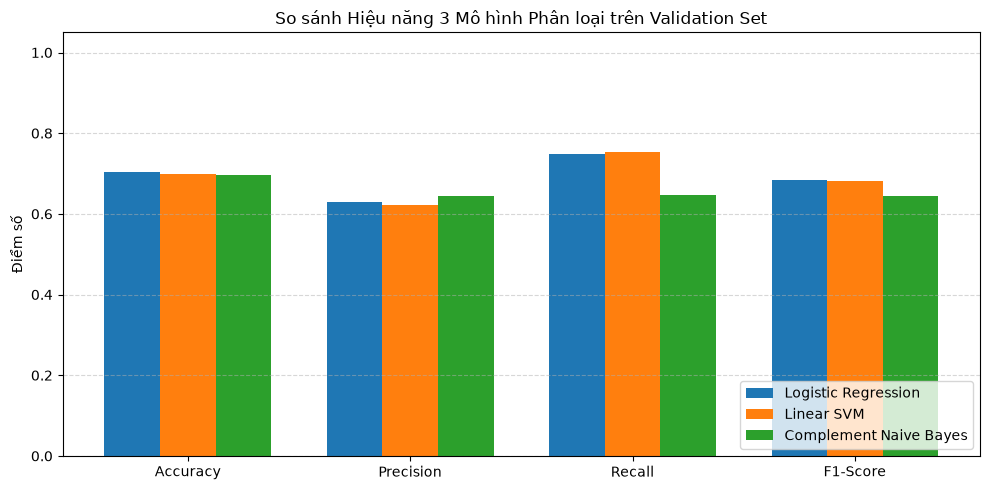

In [5]:
# Bảng tổng hợp đối sánh 3 mô hình
summary_df = evaluator.build_comparison_summary({
    'Logistic Regression': metrics_lr,
    'Linear SVM': metrics_svm,
    'Complement Naive Bayes': metrics_nb,
})
display(summary_df)

# Trực quan hóa so sánh hiệu năng trên cùng một biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))
metrics_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_plot))
width = 0.25

for idx, row in summary_df.iterrows():
    vals = [row[m] for m in metrics_plot]
    ax.bar(x + idx * width, vals, width, label=row['Mô hình'])

ax.set_ylabel('Điểm số')
ax.set_title('So sánh Hiệu năng 3 Mô hình Phân loại trên Validation Set')
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_plot)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Lưu baseline và nhận xét
Test chưa được đánh giá. Notebook 04 sẽ dùng chính các mô hình này để so sánh trước/sau tuning.


Baseline có Validation F1 cao nhất: Logistic Regression
Loss khác thang đo giữa thuật toán; không dùng độ cao đường loss để chọn mô hình.


<ipython-input-6-d9ba0d649612>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.legend(); plt.tight_layout(); plt.show()


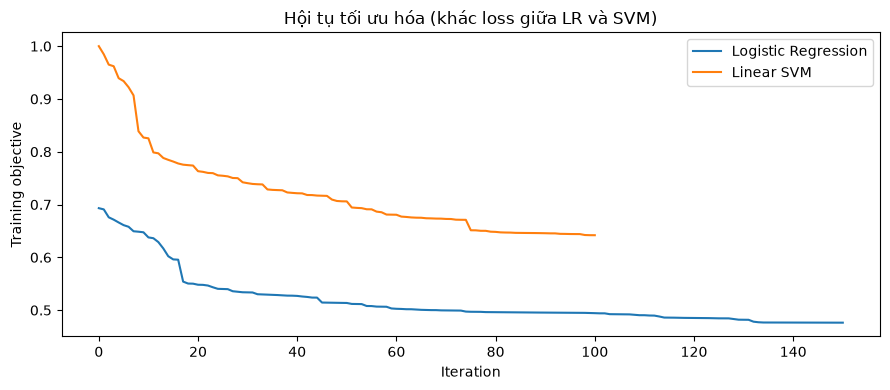

In [6]:
baseline_models = {'Logistic Regression':lr_model, 'Linear SVM':svm_model, 'Complement Naive Bayes':nb_model}
save_spam_pipeline({'run_id':artifacts['run_id'], 'models':baseline_models}, NOTEBOOK_SAVED_MODELS_DIR / 'baseline_models.joblib')
summary_df.to_csv(NOTEBOOK_METRICS_DIR / 'baseline_validation.csv', index=False)
print('Baseline có Validation F1 cao nhất:', summary_df.iloc[0]['Mô hình'])
fig, ax = plt.subplots(figsize=(9,4))
for name, model in baseline_models.items():
    history = getattr(model,'loss_history_',None)
    if history is not None and len(history): ax.plot(history,label=name)
ax.set(xlabel='Iteration',ylabel='Training objective',title='Hội tụ tối ưu hóa (khác loss giữa LR và SVM)')
ax.legend(); plt.tight_layout(); plt.show()
print('Loss khác thang đo giữa thuật toán; không dùng độ cao đường loss để chọn mô hình.')
